In [3]:
import numpy as np

# -----------------------------------------
# 1. Generate S-layer patterns
# -----------------------------------------

def generate_S_patterns(N_S, P, f_S, noise_std=0.0):
    """
    S-layer patterns as in the PDF:
    a_S^mu = binary-sparse cluster center + optional noise.
    """
    # Cluster centers (Bernoulli(f_S))
    centers = (np.random.rand(P, N_S) < f_S).astype(float)
    
    # Add optional Gaussian noise (PDF leaves noise unspecified)
    noise = noise_std * np.random.randn(P, N_S)
    
    a_S = np.clip(centers + noise, 0, None)  # enforce non-negativity
    return a_S  # shape (P, N_S)

# -----------------------------------------
# 2. Build sparse FF connectivity
# -----------------------------------------

def build_sparse_connectivity(N_R, N_S, p, J_mean, J_std):
    """
    Build Q (adjacency) and J (weights) with the correct scaling:
       J_ij ~ Normal(J_mean/sqrt(N_S), J_std/sqrt(N_S))
    and Q_ij Bernoulli(p).
    """
    Q = (np.random.rand(N_R, N_S) < p).astype(float)
    J = (J_mean/np.sqrt(N_S)) + (J_std/np.sqrt(N_S)) * np.random.randn(N_R, N_S)
    return Q, J

# -----------------------------------------
# 3. FF current computation
# -----------------------------------------

def compute_currents(a_S, Q, J, K):
    """
    H_i^mu = (1/sqrt(K)) sum_j Q_ij J_ij a_S_j.
    a_S has shape (P, N_S)
    Returns H of shape (P, N_R)
    """
    return (a_S @ (Q * J).T) / np.sqrt(K)

# -----------------------------------------
# 4. Threshold selection for target sparsity f_R
# -----------------------------------------

def choose_threshold(H, f_R):
    """
    Choose threshold T so that the resulting R activity has mean fraction f_R.
    """
    # Use quantile so that exactly f_R of units exceed T
    T = np.quantile(H, 1 - f_R)  
    return T

# -----------------------------------------
# 5. Apply ReLU
# -----------------------------------------

def relu(H, T):
    return np.maximum(H - T, 0)

# -----------------------------------------
# 6. Train perceptron readout
# -----------------------------------------

def train_perceptron(a_R, y, lr=1.0, epochs=10):
    """
    Standard perceptron learning on R-layer features.
    a_R: shape (P, N_R)
    y: labels in {-1, +1}
    """
    P, N_R = a_R.shape
    w = np.zeros(N_R)

    for _ in range(epochs):
        for mu in range(P):
            if y[mu] * (np.dot(w, a_R[mu])) <= 0:
                w += lr * y[mu] * a_R[mu]
    return w

# -----------------------------------------
# 7. Participation ratio dim (Eq. C2)
# -----------------------------------------

def participation_ratio(X):
    """
    Compute dimensionality via participation ratio (Eq. C2 from Appendix C).
    X has shape (P, N_R) = patterns × neurons
    """
    # Centering across patterns
    Xc = X - X.mean(axis=0, keepdims=True)

    # Covariance across patterns
    C = (Xc.T @ Xc) / X.shape[0]

    Cii = np.diag(C)
    Cij2 = (C**2)
    num = (Cii.mean())**2
    den = (Cij2.diagonal().mean() + (X.shape[1]-1)*((Cij2.sum() - Cij2.diagonal().sum())/(X.shape[1]**2 - X.shape[1])))
    
    return X.shape[1] * num / den

def perceptron_error(w, a_R, y):
    preds = np.sign(a_R @ w)
    return np.mean(preds != y)


In [20]:
# Experiment: error vs R sparsity
# ---------------------------

# System size
N_S = 1000
N_R = 10000
P = 1000

# FF connectivity
p = 1
K = int(p * N_S)
J_mean = 10.0/np.sqrt(N_S)
J_std = 2.0/np.sqrt(N_S)

# Build connectivity once
Q, J = build_sparse_connectivity(N_R, N_S, p, J_mean, J_std)

# Generate S-layer patterns once
f_S = 0.5
a_S = generate_S_patterns(N_S, P, f_S)

# Labels
y = np.random.choice([-1, +1], size=P)

# R-layer sparsity values
f_values = np.linspace(0.001, 0.3, 20)

errors = []

for f_R in f_values:
    H = compute_currents(a_S, Q, J, K)

    # threshold to enforce R sparsity f_R
    T = choose_threshold(H, f_R)

    # R layer
    a_R = relu(H, T)

    # perceptron
    w = train_perceptron(a_R, y)

    # classification error
    err = perceptron_error(w, a_R, y)
    errors.append(err)

# "errors" now holds the perceptron error for each R-layer sparsity
print("R-layer sparsity values:", f_values)
print("Perceptron errors:", errors)


R-layer sparsity values: [0.001      0.01673684 0.03247368 0.04821053 0.06394737 0.07968421
 0.09542105 0.11115789 0.12689474 0.14263158 0.15836842 0.17410526
 0.18984211 0.20557895 0.22131579 0.23705263 0.25278947 0.26852632
 0.28426316 0.3       ]
Perceptron errors: [np.float64(0.997), np.float64(0.929), np.float64(0.858), np.float64(0.817), np.float64(0.792), np.float64(0.743), np.float64(0.717), np.float64(0.694), np.float64(0.688), np.float64(0.669), np.float64(0.672), np.float64(0.652), np.float64(0.623), np.float64(0.581), np.float64(0.585), np.float64(0.536), np.float64(0.546), np.float64(0.48), np.float64(0.477), np.float64(0.489)]


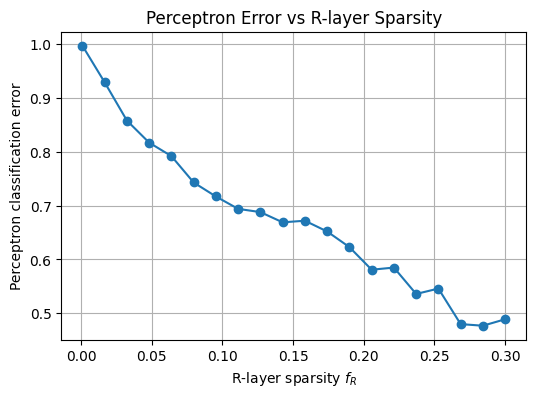

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.plot(f_values, errors, marker='o')
plt.xlabel("R-layer sparsity $f_R$")
plt.ylabel("Perceptron classification error")
plt.title("Perceptron Error vs R-layer Sparsity")
plt.grid(True)
plt.show()


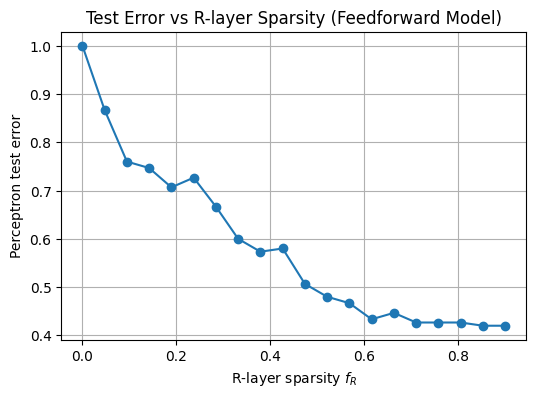

In [28]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# FF model components
# -------------------------------------------------------------

def generate_S_patterns(N_S, P, f_S, noise_std=0.0):
    centers = (np.random.rand(P, N_S) < f_S).astype(float)
    noise = noise_std * np.random.randn(P, N_S)
    return np.clip(centers + noise, 0, None)

def build_sparse_connectivity(N_R, N_S, p, J_mean, J_std):
    Q = (np.random.rand(N_R, N_S) < p).astype(float)
    J = (J_mean/np.sqrt(N_S)) + (J_std/np.sqrt(N_S))*np.random.randn(N_R, N_S)
    return Q, J

def compute_currents(a_S, Q, J, K):
    return (a_S @ (Q * J).T) / np.sqrt(K)

def choose_threshold(H, f_R):
    return np.quantile(H, 1 - f_R)

def relu(H, T):
    return np.maximum(H - T, 0)

def train_perceptron(a_R, y, lr=1.0, epochs=5):
    P, N_R = a_R.shape
    w = np.zeros(N_R)
    for _ in range(epochs):
        for mu in range(P):
            if y[mu] * (np.dot(w, a_R[mu])) <= 0:
                w += lr * y[mu] * a_R[mu]
    return w

def perceptron_error(w, a_R, y):
    preds = np.sign(a_R @ w)
    return np.mean(preds != y)


# -------------------------------------------------------------
# Experiment parameters
# -------------------------------------------------------------

N_S = 1000
N_R = 10000
P_train = 550
P_test = 150

f_S = 0.5

p = 1
K = int(p * N_S)
J_mean = 10.0/np.sqrt(N_S)
J_std = 2.0/np.sqrt(N_S)

# Build connectivity once
Q, J = build_sparse_connectivity(N_R, N_S, p, J_mean, J_std)

# Training patterns
a_S_train = generate_S_patterns(N_S, P_train, f_S)
y_train = np.random.choice([-1, +1], size=P_train)

# Test patterns (independent)
a_S_test = generate_S_patterns(N_S, P_test, f_S)
y_test = np.random.choice([-1, +1], size=P_test)

# Sparsity sweep (R-layer)
f_values = np.linspace(0.001, 0.9, 20)
test_errors = []

# -------------------------------------------------------------
# Loop over R-layer sparsity
# -------------------------------------------------------------
for f_R in f_values:

    # --- Train set ---
    H_train = compute_currents(a_S_train, Q, J, K)
    T = choose_threshold(H_train, f_R)
    a_R_train = relu(H_train, T)

    # Train perceptron
    w = train_perceptron(a_R_train, y_train)

    # --- Test set ---
    H_test = compute_currents(a_S_test, Q, J, K)
    a_R_test = relu(H_test, T)    # same threshold!
    err_test = perceptron_error(w, a_R_test, y_test)

    test_errors.append(err_test)

# -------------------------------------------------------------
# Plot
# -------------------------------------------------------------
plt.figure(figsize=(6,4))
plt.plot(f_values, test_errors, marker='o')
plt.xlabel("R-layer sparsity $f_R$")
plt.ylabel("Perceptron test error")
plt.title("Test Error vs R-layer Sparsity (Feedforward Model)")
plt.grid(True)
plt.show()
